In [207]:
import matplotlib.pyplot as plt
import timeit
import numpy as np
import pandas as pd
import scipy.stats
import seaborn as sns
import sklearn.metrics
import sklearn.preprocessing as preprocessing
from sklearn import datasets,linear_model
from sklearn.preprocessing import StandardScaler

In [208]:
processors=pd.read_csv(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\sena\Transformación de datos en modelos de inteligencia\2025_09_05_Processors.csv',sep=';')
processors.info()

<class 'pandas.DataFrame'>
RangeIndex: 1028 entries, 0 to 1027
Data columns (total 52 columns):
 #   Column                               Non-Null Count  Dtype
---  ------                               --------------  -----
 0   Designer                             1028 non-null   str  
 1   Serie                                684 non-null    str  
 2   Type                                 1028 non-null   str  
 3   Codename                             236 non-null    str  
 4   Year Released                        1028 non-null   int64
 5   Function                             1028 non-null   str  
 6   Width of Machine Word                1028 non-null   str  
 7   Supported Instruction Set(s)         1027 non-null   str  
 8   Type of processor core(s)            1022 non-null   str  
 9   Number of processor core(s)          1028 non-null   int64
 10  Memory Interface(s)                  1028 non-null   str  
 11  Max. Clock Frequency of Memory IF    551 non-null    str  
 12  Dat

In [209]:
processors_df=processors[['Designer','Type','Year Released','Function','Width of Machine Word','Number of processor core(s)','Memory Interface(s)','Semiconductor Technology','Supported GPS protocol(s)']]
processors_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1028 entries, 0 to 1027
Data columns (total 9 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   Designer                     1028 non-null   str  
 1   Type                         1028 non-null   str  
 2   Year Released                1028 non-null   int64
 3   Function                     1028 non-null   str  
 4   Width of Machine Word        1028 non-null   str  
 5   Number of processor core(s)  1028 non-null   int64
 6   Memory Interface(s)          1028 non-null   str  
 7   Semiconductor Technology     1028 non-null   str  
 8   Supported GPS protocol(s)    1028 non-null   str  
dtypes: int64(2), str(7)
memory usage: 72.4 KB


In [210]:
aux=[]
for i in range(0,processors_df.shape[0]):
    cad=processors_df.iloc[i,4]
    #print(cad,len(cad))
    if len(cad)<6:
        aux.append(int(cad[0:1]))
    else:
        aux.append(int(cad[0:2]))
#print(aux)

processors_df['Width of Machine Word (bits)']=aux

processors_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1028 entries, 0 to 1027
Data columns (total 10 columns):
 #   Column                        Non-Null Count  Dtype
---  ------                        --------------  -----
 0   Designer                      1028 non-null   str  
 1   Type                          1028 non-null   str  
 2   Year Released                 1028 non-null   int64
 3   Function                      1028 non-null   str  
 4   Width of Machine Word         1028 non-null   str  
 5   Number of processor core(s)   1028 non-null   int64
 6   Memory Interface(s)           1028 non-null   str  
 7   Semiconductor Technology      1028 non-null   str  
 8   Supported GPS protocol(s)     1028 non-null   str  
 9   Width of Machine Word (bits)  1028 non-null   int64
dtypes: int64(3), str(7)
memory usage: 80.4 KB


In [211]:
processors_df['Semiconductor Technology'].value_counts()

Semiconductor Technology
CMOS      867
FinFET    153
HMOS        5
Yes         2
No          1
Name: count, dtype: int64

In [212]:
for i in range(0,processors_df.shape[0]):
    if (processors_df.iloc[i,7]=='Yes' or processors_df.iloc[i,7]=='No'):
        processors_df.iloc[i,7]='CMOS'

processors_df['Semiconductor Technology'].value_counts()

Semiconductor Technology
CMOS      870
FinFET    153
HMOS        5
Name: count, dtype: int64

In [213]:
processors_decoded=pd.get_dummies(processors_df, columns=['Semiconductor Technology'],dtype=int)
processors_decoded.info()

<class 'pandas.DataFrame'>
RangeIndex: 1028 entries, 0 to 1027
Data columns (total 12 columns):
 #   Column                           Non-Null Count  Dtype
---  ------                           --------------  -----
 0   Designer                         1028 non-null   str  
 1   Type                             1028 non-null   str  
 2   Year Released                    1028 non-null   int64
 3   Function                         1028 non-null   str  
 4   Width of Machine Word            1028 non-null   str  
 5   Number of processor core(s)      1028 non-null   int64
 6   Memory Interface(s)              1028 non-null   str  
 7   Supported GPS protocol(s)        1028 non-null   str  
 8   Width of Machine Word (bits)     1028 non-null   int64
 9   Semiconductor Technology_CMOS    1028 non-null   int64
 10  Semiconductor Technology_FinFET  1028 non-null   int64
 11  Semiconductor Technology_HMOS    1028 non-null   int64
dtypes: int64(6), str(6)
memory usage: 96.5 KB


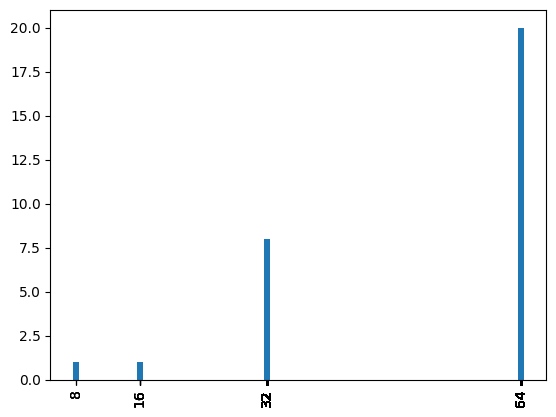

In [214]:
plt.bar(processors_decoded['Width of Machine Word (bits)'],processors_decoded['Number of processor core(s)'])
plt.xticks(processors_df['Width of Machine Word (bits)'],rotation=90)
plt.show()

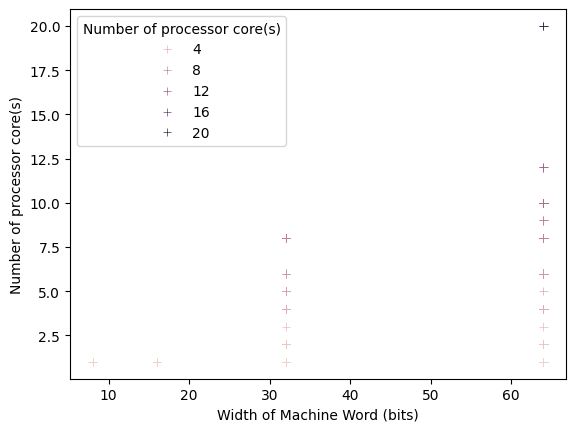

In [215]:
sns.scatterplot(data=processors_decoded, x='Width of Machine Word (bits)', marker='+',y='Number of processor core(s)', hue='Number of processor core(s)')
plt.show()

### se debe hallar el valor óptimo de K
### se aplica el método del codo para hallar K
### Se calcula el algoritmo de agrupacion para diferentes valores de K

In [216]:
import warnings
warnings.filterwarnings('ignore')
from sklearn.cluster import KMeans

In [217]:
processors_kmeans=processors_decoded[['Width of Machine Word (bits)','Number of processor core(s)']]
processors_kmeans.info()

<class 'pandas.DataFrame'>
RangeIndex: 1028 entries, 0 to 1027
Data columns (total 2 columns):
 #   Column                        Non-Null Count  Dtype
---  ------                        --------------  -----
 0   Width of Machine Word (bits)  1028 non-null   int64
 1   Number of processor core(s)   1028 non-null   int64
dtypes: int64(2)
memory usage: 16.2 KB


In [ ]:
#Se elige aleatoriamente con cualquier mecanismo el registro 0, el registro 512 y el registro 1000, usando la función loc del dataframe:
indiceMuestra =[0,512,1000]
muestras = pd.DataFrame (processors_kmeans.loc[indiceMuestra], columns = processors_kmeans.keys()).reset_index(drop =True)
muestras

,Width of Machine Word (bits),Number of processor core(s)
0,64,10
1,64,8
2,32,1


In [ ]:
#Una vez escogidas las muestras, estas se eliminan de la data original processors_df, de los datos de muestra, para que estos no se integren con el resto de la información.
processors_kmeans=processors_kmeans.drop(indiceMuestra, axis = 0)

In [220]:
X = processors_kmeans.iloc[:, [0,1]].values
X

array([[64,  8],
       [64,  8],
       [64,  8],
       ...,
       [ 8,  1],
       [ 8,  1],
       [32,  1]], shape=(1025, 2))

In [221]:
inercia =[] # suma de cuadrados
for i in range (1,20): 
        algoritmo = KMeans (n_clusters  = i, max_iter =300).fit(X)
        inercia.append(algoritmo.inertia_)

<function matplotlib.pyplot.show(close=None, block=None)>

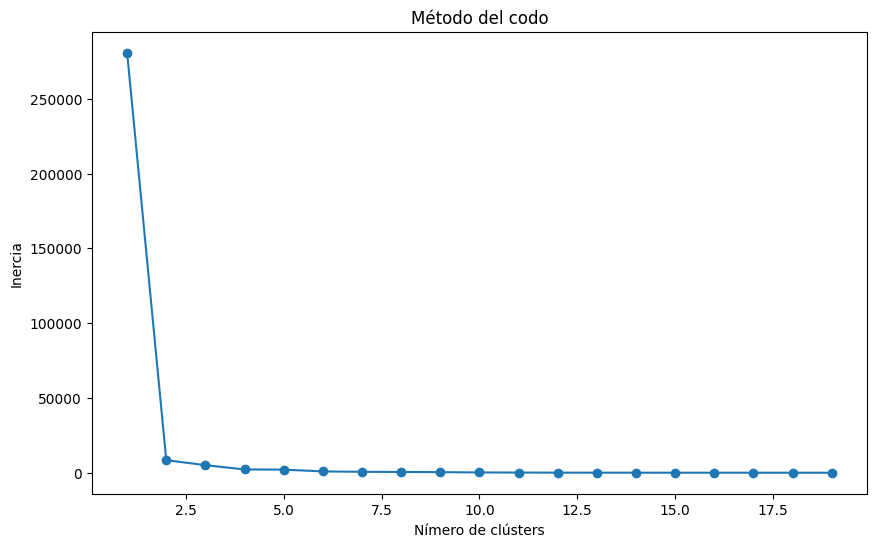

In [222]:
plt.figure(figsize =[10,6])
plt.title('Método del codo')
plt.xlabel('Nímero de clústers')
plt.ylabel('Inercia')
plt.plot ( list(range(1,20)), inercia, marker='o')
plt.show


In [ ]:
#n_clusters = 2 porque según el gráfico anterior, el codo está entre 2.5 y 5, se tomó k=3 entonces.
algoritmo = KMeans( n_clusters=2, init ='k-means++', max_iter=300, n_init =10)

In [224]:
algoritmo.fit(X)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",2
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary `.",None
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'


In [225]:
centroides, etiquetas = algoritmo.cluster_centers_, algoritmo.labels_

In [226]:
centroides

array([[31.65413534,  2.03383459],
       [64.        ,  6.32251521]])

In [227]:
etiquetas

array([1, 1, 1, ..., 0, 0, 0], shape=(1025,), dtype=int32)

In [228]:
Xmuestras = muestras.iloc[:, [0, 1]].values
YMuestraPrediccion = algoritmo.predict (Xmuestras)
Xmuestras

array([[64, 10],
       [64,  8],
       [32,  1]])

In [229]:
print (YMuestraPrediccion)

[1 1 0]


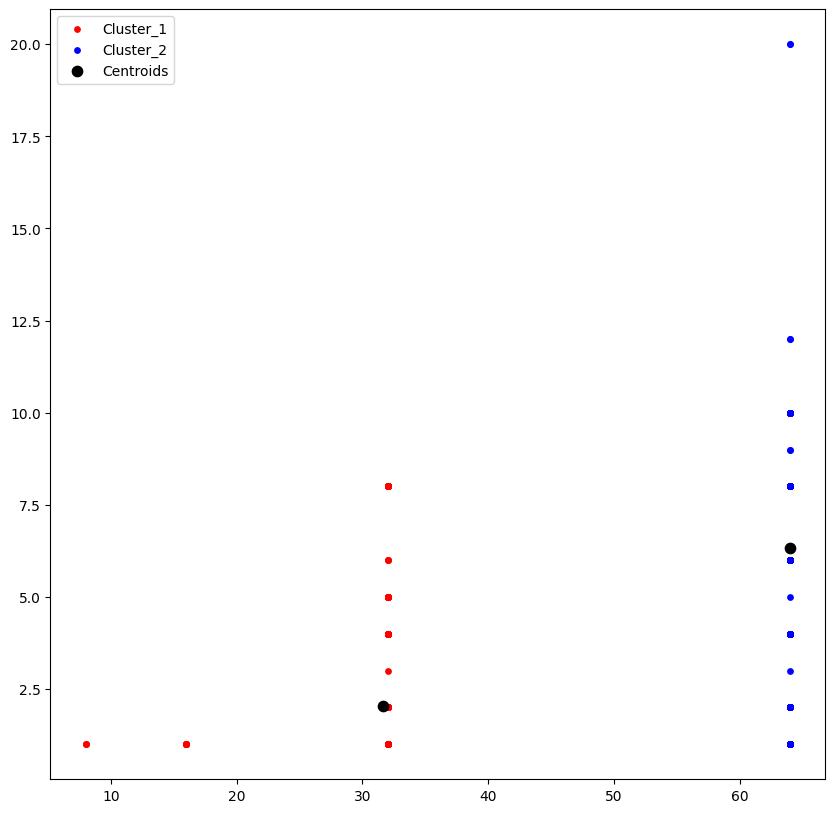

In [230]:
#Aplicando k-means al dataset / creacion del clasificador con k-means
plt.figure(figsize =[10,10])
plt.scatter(X[etiquetas == 0,0], X[etiquetas==0,1], s = 15, c= 'red', label = 'Cluster_1')
plt.scatter(X[etiquetas== 1,0], X[etiquetas==1,1], s = 15, c= 'blue', label = 'Cluster_2')
plt.scatter(centroides[:,0], centroides[:,1], s = 55, c = 'black', label = 'Centroids')
plt.legend()
plt.show()